# Task 3 — Transaction Intensity

## Analytical Question

**How many transactions were generated per active address?**

Transaction intensity is calculated as:

**Transactions per active address = Daily transactions / Daily active addresses**

This metric measures the average number of transactions associated with each active address per day. It does not mean that every address actually made that exact number of transactions.


## Data

This task combines the two analytical datasets already produced:

- `data/processed/daily_transactions.csv`
- `data/processed/daily_active_addresses.csv`

No new large blockchain dataset needs to be loaded into Pandas. The daily analytical results are sufficient for this calculation.

In [34]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas.io.formats.format as pf
# Force Pandas' internal integer formatter to use commas seperator globally
class CommaIntFormatter(pf._GenericArrayFormatter):
    def _format_strings(self):
        formatter = self.formatter or '{:,d}'.format
        return [formatter(x) for x in self.values]

# Override the default engine
pf._IntArrayFormatter = CommaIntFormatter

# Format float with comma(removes E-notation)
pd.set_option('display.float_format', lambda x: f' {x:,.2f}')

## Load the Analytical Datasets

In [35]:
import pandas as pd

transactions = pd.read_csv(
    "../data/processed/daily_transactions.csv"
)

active_addresses = pd.read_csv(
    "../data/processed/daily_active_addresses.csv"
)

In [36]:
transactions.head()

,date,transaction_count
0,2026-08-24,"1,157,222"
1,2026-08-25,"1,994,723"
2,2026-08-26,"1,898,276"
3,2026-08-27,"1,931,985"
4,2026-08-28,"1,902,964"


In [37]:
active_addresses.head()

,date,active_addresses
0,2026-08-24,"421,690"
1,2026-08-25,"672,803"
2,2026-08-26,"612,723"
3,2026-08-27,"645,948"
4,2026-08-28,"616,346"


## Validate the Input Data

Check the shape, columns, data types, missing values, and duplicate dates before combining the datasets.

In [38]:
print("Transactions:", transactions.shape)
print("Active addresses:", active_addresses.shape)

print("\nTransactions columns:")
print(transactions.columns)

print("\nActive-address columns:")
print(active_addresses.columns)

Transactions: (31, 2)
Active addresses: (31, 2)

Transactions columns:
Index(['date', 'transaction_count'], dtype='object')

Active-address columns:
Index(['date', 'active_addresses'], dtype='object')


In [39]:
print("Transactions missing values:")
print(transactions.isna().sum())

print("\nActive-address missing values:")
print(active_addresses.isna().sum())

print("\nDuplicate transaction dates:", transactions["date"].duplicated().sum())
print("Duplicate active-address dates:", active_addresses["date"].duplicated().sum())

Transactions missing values:
date                0
transaction_count   0
dtype: int64

Active-address missing values:
date               0
active_addresses   0
dtype: int64

Duplicate transaction dates: 0
Duplicate active-address dates: 0


## Prepare the Date Columns

In [40]:
transactions["date"] = pd.to_datetime(transactions["date"])
active_addresses["date"] = pd.to_datetime(active_addresses["date"])

## Merge the Analytical Datasets

Combine the daily transaction counts and daily active addresses using the shared `date` column.

In [41]:
df = transactions.merge(
    active_addresses,
    on="date",
    how="left"
)

df.head()

,date,transaction_count,active_addresses
0,2026-08-24,"1,157,222","421,690"
1,2026-08-25,"1,994,723","672,803"
2,2026-08-26,"1,898,276","612,723"
3,2026-08-27,"1,931,985","645,948"
4,2026-08-28,"1,902,964","616,346"


In [42]:
df.shape
df.isna().sum()


date                0
transaction_count   0
active_addresses    0
dtype: int64

## Calculate Transactions per Active Address

In [43]:
df["transactions_per_active_address"] = (
    df["transaction_count"] / df["active_addresses"]
)

df[["date", "transaction_count", "active_addresses", "transactions_per_active_address"]].head()

,date,transaction_count,active_addresses,transactions_per_active_address
0,2026-08-24,"1,157,222","421,690",2.74
1,2026-08-25,"1,994,723","672,803",2.96
2,2026-08-26,"1,898,276","612,723",3.10
3,2026-08-27,"1,931,985","645,948",2.99
4,2026-08-28,"1,902,964","616,346",3.09


## Handle Partial Days

The 30-day analysis window produces two partial calendar days: the starting date and ending date. For comparable daily analysis, exclude these two partial days.

In [44]:
# The two partial days
first_day = df["date"].min()
last_day = df["date"].max()

# keep only complete days
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)]
complete_days.shape

(29, 4)

In [45]:
# .copy() creates an independent DataFrame that we can safely modify.
complete_days = df[(df["date"] > first_day) & (df["date"] < last_day)].copy()

## Baseline Statistics

Calculate the central tendency and identify the highest and lowest transaction-intensity days.

In [46]:
mean_intensity = complete_days["transactions_per_active_address"].mean()
median_intensity = complete_days["transactions_per_active_address"].median()

mean_intensity, median_intensity

(np.float64(3.0137565084024476), np.float64(2.987107795318504))

In [47]:
highest_day = complete_days.loc[
    complete_days["transactions_per_active_address"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["transactions_per_active_address"].idxmin()
]

highest_day, lowest_day

(date                               2026-08-30 00:00:00
 transaction_count                              1794571
 active_addresses                                507424
 transactions_per_active_address                   3.54
 Name: 6, dtype: object,
 date                               2026-09-10 00:00:00
 transaction_count                              2096674
 active_addresses                                829303
 transactions_per_active_address                   2.53
 Name: 17, dtype: object)

## First-to-Last Change

Compare transaction intensity on the first and last complete days.

In [48]:
first_intensity = complete_days.iloc[0]["transactions_per_active_address"]
last_intensity = complete_days.iloc[-1]["transactions_per_active_address"]

first_to_last_pct = (
    (last_intensity - first_intensity) / first_intensity * 100
)

first_to_last_pct

np.float64(-3.3958160217916324)

## Seven-Day Rolling Average

Use a rolling average to identify the broader movement in transaction intensity rather than relying only on individual daily observations.

In [49]:
complete_days["rolling_7d"] = (
    complete_days["transactions_per_active_address"]
    .rolling(7)
    .mean()
)

complete_days[["date", "transactions_per_active_address", "rolling_7d"]].tail(10)

,date,transactions_per_active_address,rolling_7d
20,2026-09-13,3.25,2.90
21,2026-09-14,2.96,2.91
22,2026-09-15,3.06,2.91
23,2026-09-16,2.99,2.93
24,2026-09-17,2.91,2.99
25,2026-09-18,2.95,3.03
26,2026-09-19,3.35,3.07
27,2026-09-20,3.00,3.03
28,2026-09-21,2.99,3.04
29,2026-09-22,2.86,3.01


## Visualization

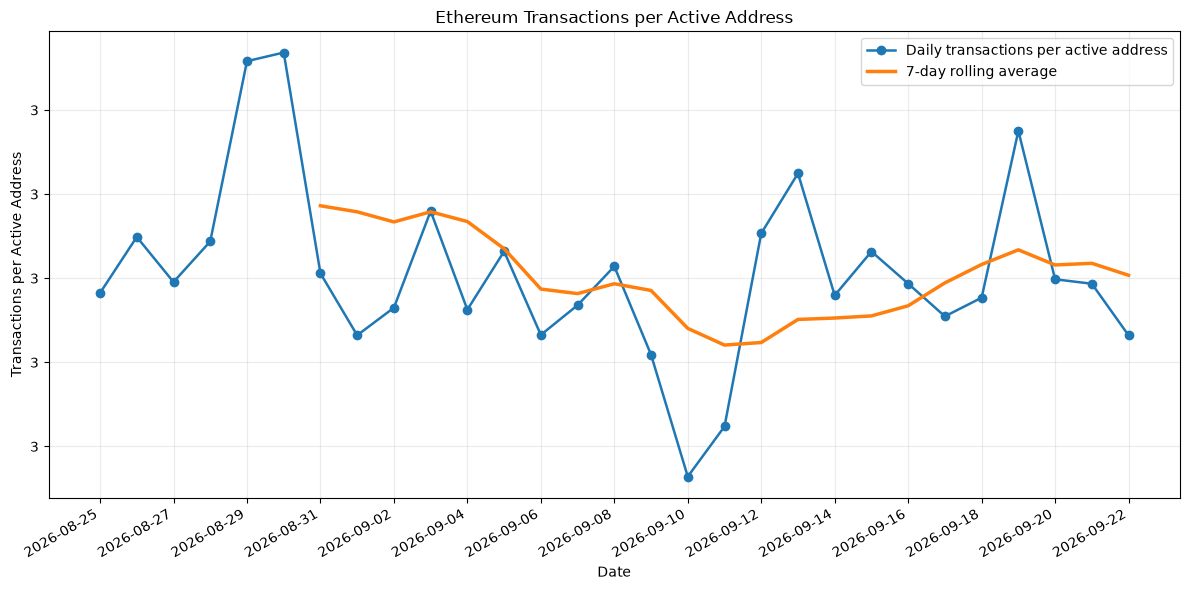

In [50]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    complete_days["date"],
    complete_days["transactions_per_active_address"],
    marker="o",
    linewidth=1.8,
    label="Daily transactions per active address"
)

ax.plot(
    complete_days["date"],
    complete_days["rolling_7d"],
    linewidth=2.5,
    label="7-day rolling average"
)

# Format y-axis with commas
ax.yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

# Show every 2nd date
ax.set_xticks(complete_days["date"][::2])

ax.set_title("Ethereum Transactions per Active Address")
ax.set_xlabel("Date")
ax.set_ylabel("Transactions per Active Address")
ax.legend()
ax.grid(alpha=0.25)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Plotly Visualization


In [51]:
import plotly.express as px


# Prepare data for visualization
plot_df = complete_days[
    ["date", "transactions_per_active_address", "rolling_7d"]
].copy()

plot_df = plot_df.rename(
    columns={
        "transactions_per_active_address": "Daily transactions per active address",
        "rolling_7d": "7-day rolling average"
    }
)

plot_df = plot_df.melt(
    id_vars="date",
    var_name="metric",
    value_name="transactions_per_address"
)


# Identify highest and lowest intensity days
highest_day = complete_days.loc[
    complete_days["transactions_per_active_address"].idxmax()
]

lowest_day = complete_days.loc[
    complete_days["transactions_per_active_address"].idxmin()
]


# Create the line chart
fig = px.line(
    plot_df,
    x="date",
    y="transactions_per_address",
    color="metric",
    title="Ethereum Transactions per Active Address, Aug 25 – Sep 22, 2026",
    markers=True,
    labels={
        "date": "Date",
        "transactions_per_address": "Transactions per active address",
        "metric": ""
    }
)


# Chart layout
fig.update_layout(
    template="plotly_dark",
    hovermode="x unified",
    height=600,

    margin=dict(
        l=70,
        r=40,
        t=110,
        b=100
    ),

    xaxis=dict(
        title="Date",
        hoverformat="%b %d, %Y",
        tickmode="auto",
        nticks=20,
        tickformat="%b %d",
        tickangle=-45
    ),

    yaxis=dict(
        title="Transactions per active address",
        fixedrange=True
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="left",
        x=0
    )
)


# Format markers and hover information
fig.update_traces(
    marker=dict(size=6),
    hovertemplate=(
        "<b>%{fullData.name}</b>: "
        "%{y:.3f} transactions/address"
        "<extra></extra>"
    )
)


# Add highest-intensity marker
fig.add_scatter(
    x=[highest_day["date"]],
    y=[highest_day["transactions_per_active_address"]],
    mode="markers+text",
    text=["Highest"],
    textposition="top right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Highest intensity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.3f} transactions/address"
        "<extra></extra>"
    )
)


# Add lowest-intensity marker
fig.add_scatter(
    x=[lowest_day["date"]],
    y=[lowest_day["transactions_per_active_address"]],
    mode="markers+text",
    text=["Lowest"],
    textposition="bottom right",
    marker=dict(size=11),
    showlegend=False,
    hovertemplate=(
        "<b>Lowest intensity</b><br>"
        "%{x|%b %d, %Y}<br>"
        "%{y:.3f} transactions/address"
        "<extra></extra>"
    )
)


# Add padding to the y-axis so annotations are not clipped
y_min = complete_days["transactions_per_active_address"].min()
y_max = complete_days["transactions_per_active_address"].max()
padding = (y_max - y_min) * 0.15

fig.update_yaxes(
    range=[
        y_min - padding,
        y_max + padding
    ]
)


# Display the chart
fig.show()

## Variability

In [52]:
std_intensity = complete_days["transactions_per_active_address"].std()
cv_intensity = (
    std_intensity / mean_intensity * 100
)

std_intensity, cv_intensity

(np.float64(0.21214410407454523), np.float64(7.039191901637734))

## Finding | Evidence | Meaning
### Finding

Ethereum's transaction intensity remained relatively stable across the 29 complete days, averaging about **3.01 transactions per active address per day**, with noticeable day-to-day variation. The metric declined slightly from the first to the last complete day.

### Evidence

- **Mean:** 3.014 transactions per active address
- **Median:** 2.987
- **Highest:** August 30 — **3.537**
- **Lowest:** September 10 — **2.528**
- **First complete day:** August 25 — **2.965**
- **Last complete day:** September 22 — **2.864**
- **First-to-last change:** **-3.40%**
- **Standard deviation:** 0.212
- **Coefficient of variation:** **7.04%**

The 7-day rolling average stayed close to 3 transactions per active address, indicating that the broader level of transaction intensity was relatively stable despite individual daily fluctuations.

### Meaning

The results indicate that changes in Ethereum's daily transaction count were broadly accompanied by changes in the number of active addresses, leaving the average transaction intensity per active address within a relatively narrow range.

This metric describes the relationship between **daily transaction volume and daily active addresses**. It does not mean that each address actually made the calculated number of transactions, and it should not be interpreted as a measure of individual user behavior.


## Limitations

- The analysis covers only a **30-day period**, so the observed transaction-intensity pattern does not establish a longer-term trend.

- **Transactions per active address is an aggregate ratio**, calculated as daily transactions divided by daily active addresses. It does not mean that each active address actually generated that exact number of transactions.

- **Active addresses are not equivalent to unique users.** One entity may control multiple addresses, while an address may represent a contract or another type of participant.

- The **first and last calendar dates are partial days** because the analysis window begins and ends at 10:01:35 UTC. These boundary dates were therefore excluded from comparable daily analysis.

- The analysis identifies **changes in transaction intensity but does not establish their causes**. Additional analysis would be required to determine why intensity increased or decreased on particular days.